In [28]:
import re
import os
import jpype
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import learning_curve
import nltk
from nltk.corpus import stopwords
ZEMBEREK_PATH="zemberek-full.jar"

In [29]:
os.environ["JAVA_HOME"]=r"C:\Program Files\Java\jdk-17"
if not jpype.isJVMStarted():
    jpype.startJVM(
        jpype.getDefaultJVMPath(),
        "-ea",
        f"-Djava.class.path={ZEMBEREK_PATH}",
        ignoreUnrecognized=True
    )

In [30]:
nltk.download('stopwords')
TurkishSentenceExtractor=jpype.JClass('zemberek.tokenization.TurkishSentenceExtractor')
TurkishMorphology=jpype.JClass('zemberek.morphology.TurkishMorphology')
TurkishSpellChecker=jpype.JClass('zemberek.normalization.TurkishSpellChecker')
TurkishTokenizer=jpype.JClass('zemberek.tokenization.TurkishTokenizer')
TurkishLexer=jpype.JClass('zemberek.tokenization.antlr.TurkishLexer')

extractor=TurkishSentenceExtractor.DEFAULT
morphology=TurkishMorphology.createWithDefaults()
tokenizer=TurkishTokenizer.ALL
spell=TurkishSpellChecker(morphology)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\zynpe\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [31]:
stop_words=nltk.corpus.stopwords.words('turkish')


In [32]:
def preprocess(text):
    if isinstance(text, list):
        text=text[0] if len(text)>0 else ""
    text=re.sub(r'\b\d+\b','',text)
    text=re.sub(r'\s+','',text)
    tokens=tokenizer.tokenize(text)
    process_word=[]
    for token in tokens:
        word=str(token.getText())
        if word.isalpha() and word.lower() not in stop_words:
            analysis=morphology.analyze(word)
            analysis_list=list(analysis)
            if len(analysis_list)>0:
                best=analysis_list[0]
                try:
                    lemmatization=str(best.getStems().get(0))
                    process_word.append(lemmatization)
                except:
                    process_word.append(word)
            else:
                process_word.append(word)
    return " ".join(process_word)
                    
                    

In [33]:
df=pd.read_csv('data/dataset.csv')
print(f'Toplam makale sayısı:{len(df)}')
display(df['label'].value_counts())
display(df.head(2))

Toplam makale sayısı:6430


label
tarih                   1498
saglik                  1497
bilgisayar_bilimleri    1495
finans                  1495
spor                     445
Name: count, dtype: int64

,id,label,journal,year,title,abstract,keywords,url
0,oai:dergipark.org.tr:article/1001762,bilgisayar_bilimleri,adyujsci,2021.0,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,Bu çalışmada iki problem incelenmiştir. Genel ...,Mathematical Sciences; Matematik; Dual s- numb...,https://dergipark.org.tr/en/pub/adyujsci/artic...
1,oai:dergipark.org.tr:article/1003333,bilgisayar_bilimleri,adyujsci,2021.0,CMS Açık Veri ile Eğitici Higgs Çalışması,"Kompakt Müon Solenoid (CMS) Deneyi, CERN’in Bü...",Nuclear Physics; Nükleer Fizik; : CMS Açık Ver...,https://dergipark.org.tr/en/pub/adyujsci/artic...


In [34]:
df['full_text']=df['title'].fillna('')+". "+df['abstract'].fillna('')
df['processed_text']=df['full_text'].apply(preprocess)
display(df[['full_text','processed_text']].tail(2))

,full_text,processed_text
6428,ATATÜRK ULUSLARARASI BARIŞ ÖDÜLÜ. Savaşların n...,ATATÜRKULUSLARARASIBARIŞÖDÜLÜ Savaşlarınnedeno...
6429,TARİHSEL OLAYLARI ÇÖZÜMLEMEDE METİN MADENCİLİĞ...,TARİHSELOLAYLARIÇÖZÜMLEMEDEMETİNMADENCİLİĞİ NU...


In [35]:
x_train, x_test, y_train, y_test = train_test_split(df['processed_text'], df['label'], test_size=0.2, random_state=42)
vectorizer=TfidfVectorizer(ngram_range=(1,2),min_df=3)
x_train_vector=vectorizer.fit(x_train)
x_train_vector=vectorizer.transform(x_train)
x_test_vector=vectorizer.transform(x_test)

nb_model=MultinomialNB(alpha=0.1)
nb_model.fit(x_train_vector,y_train)
y_prediction=nb_model.predict(x_test_vector)
accuracy=accuracy_score(y_test,y_prediction)
print(f"Model Doğruluk Oranı %{accuracy * 100:.2f}\n")
print("\nSınıflandırma Raporu:\n", classification_report(y_test, y_prediction))

Model Doğruluk Oranı %74.26


Sınıflandırma Raporu:
                       precision    recall  f1-score   support

bilgisayar_bilimleri       0.82      0.66      0.73       319
              finans       0.73      0.68      0.70       304
              saglik       0.87      0.83      0.85       296
                spor       0.83      0.78      0.81        82
               tarih       0.59      0.80      0.68       285

            accuracy                           0.74      1286
           macro avg       0.77      0.75      0.75      1286
        weighted avg       0.76      0.74      0.75      1286



In [9]:
nis_metin = ["""Derin Evrişimli Sinir Ağları ve Dikkat Mekanizmaları Kullanılarak Beyin MR Görüntüleri Üzerinden Otomatik Tümör Sınıflandırması. Bu çalışmada, nörolojik hastalıkların erken teşhisi..."""]
# Ön işleme ve tahmin
islenmis = preprocess(nis_metin[0]) # Liste olduğu için [0] ile string'e ulaşıyoruz
nis_vec = vectorizer.transform([islenmis])

# Olasılıkları ve tahmini gör
tahmin = nb_model.predict(nis_vec)
olasiliklar = nb_model.predict_proba(nis_vec)

print("Tahmin Edilen Kategori:", tahmin[0])
for sinif, prob in zip(nb_model.classes_, olasiliklar[0]):
    print(f"{sinif} -> Olasılık: {prob:.4f}")

Tahmin Edilen Kategori: bilgisayar_bilimleri
bilgisayar_bilimleri -> Olasılık: 0.6285
finans -> Olasılık: 0.1582
saglik -> Olasılık: 0.0547
spor -> Olasılık: 0.0038
tarih -> Olasılık: 0.1549


In [10]:
nis_metin = ["""Günümüzde devletler yapay zeka araştırma ve geliştirme çalışmalarına ve yatırımlarına büyük önem vermektedirler. Küresel alandaki rekabetten yararlanarak dünya üzerinde hakimiyet kurmak isteyen ülkeler bu alanda yenilikleri ilk uygulayan devlet olarak üstünlük gücünü ele geçirmek amacındadırlar. Yapay zeka alanındaki küresel rekabette önemli bir yere sahip olan Çin 2017 yılında Ulusal Yapay Zeka Stratejisi’ni kamuoyuna sunması ile yapay zekaya yönelik yapılan mevcut yatırımlara resmilik kazandıran, Devlet Konseyi’nin Yapay Zeka Geliştirme Ulusal Stratejisi belgesini yayınladı. Küresel çapta yapay zeka hakimiyeti açısından oldukça büyük öneme sahip olan bu belge diğer devletleri de ulusal yapay zeka stratejisi oluşturma yönünde teşvik etti. Aynı zamanda Çin’in ülke genelinde bu alanda hızlı yaşanan bilimsel araştırma ve geliştirmeler ile eğitimin yapay zeka alanındaki yenilikler bakımından önemini vurgulayan bir nitelik de taşımaktadır. Ayrıca bu süreç, Çin’de eğitimde yapay zeka teknolojileri deney ve çalışmalarının yoğunluk kazanması, yatırım ölçeklerinin oldukça büyük oluşu, eğitimde üst seviye yapay zeka teknolojilerini geliştirmesi dünyadaki eğitimsel yapay zeka gelişimindeki güç dengelerinin yönünü değiştirmeye başladı. Şimdilerde olduğu gibi, eğitimsel yapay zekadaki gelişmelerle küresel yönden gelecekte de ne denli değiştirip dönüştüreceğinin de işaretlerini vermektedir. Dünya genelinde oldukça büyük etki yapan bu belge, pek çok ülke tarafından yapay zekanın stratejik kullanımını amaçlayan “Ulusal Yapay Zeka Stratejileri”nin hazırlanmasına neden olmuştur. Bu makalede, Çin hükümeti tarafından yayınlanan yapay zeka gelişimi için eğitim kurumlarının ulusal ve bölgesel strateji alanlarında etkin olarak yer alan Ulusal Yapay Zeka Stratejisi eğitimsel açıdan ele alınmaktadır. Hükümet politikalarına göre yapay zeka eğitimin gelişimini bir analiz yoluyla tasvir ederken, PISA sınavı sonuçları ile de bağlantı kurularak açıklanmaya çalışılmaktadır. Ayrıca Çin’deki Uluslararası Yapay Zeka Geliştirme Stratejisini eğitimsel alanda hızla uygulamalarının ve gelişmelerine yönelik yaptırımların neler olduğu onu bu yönde diğer ülkelerden ayıran özellikleri ortaya konulmaya çalışılmaktadır. Ayrıca Çin’deki bu gelişimin sadece yapay zeka teknolojilerinin tasarımı değil eğitim sisteminin değişim ve dönüşümünde etkili olan nedenler ve çözümlere ilişkin yaklaşımlara yer verilmektedir. Çin başta olmak üzere, diğer birçok ülke ulusal yapay zeka stratejisi belgelerini yayınlayarak yapay zeka alanında gelişmeyi kalkınma amaçları arasında yerleştirmişlerdir. Türkiye’de küresel çapta yaşanan yapay zekadaki hızlı gelişimin dışında olmamak için yapay zeka teknolojisine yönelik 2021 yılında Ulusal Yapay Zeka Strateji’ni yayınlayarak, eğitimsel yapay zeka teknolojisini daha fazla gelişmek zorunda kalmaktadır. Bu çalışma, Ulusal Yapay Zeka Stratejileri kapsamında eğitimde yapay zekanın gelişimi üzerine genel bir çerçeve belirleyerek yapay zeka teknolojisinin genel olarak küresel düzeyde ve Çin ile Türkiye ulusal yapay zeka stratejilerinin eğitim yönünden güçlü ve zayıf yönlerini değerlendirmektedir. Ayrıca Çin’in ulusal yapay zeka stratejisi ve eylem planında yapay zekanın eğitimsel yönünü analiz ederek Türkiye’nin eğitimsel yönden yapay zekayı merkezi alan bir ekosistem oluşturması ve gelişimini sağlayabilmesinde izleyeceği stratejiye yönelik öneriler sunmayı amaçlamaktadır."""]
# Ön işleme ve tahmin
islenmis = preprocess(nis_metin[0]) # Liste olduğu için [0] ile string'e ulaşıyoruz
nis_vec = vectorizer.transform([islenmis])

# Olasılıkları ve tahmini gör
tahmin = nb_model.predict(nis_vec)
olasiliklar = nb_model.predict_proba(nis_vec)

print("Tahmin Edilen Kategori:", tahmin[0])
for sinif, prob in zip(nb_model.classes_, olasiliklar[0]):
    print(f"{sinif} -> Olasılık: {prob:.4f}")

Tahmin Edilen Kategori: tarih
bilgisayar_bilimleri -> Olasılık: 0.3756
finans -> Olasılık: 0.0685
saglik -> Olasılık: 0.0654
spor -> Olasılık: 0.0007
tarih -> Olasılık: 0.4898


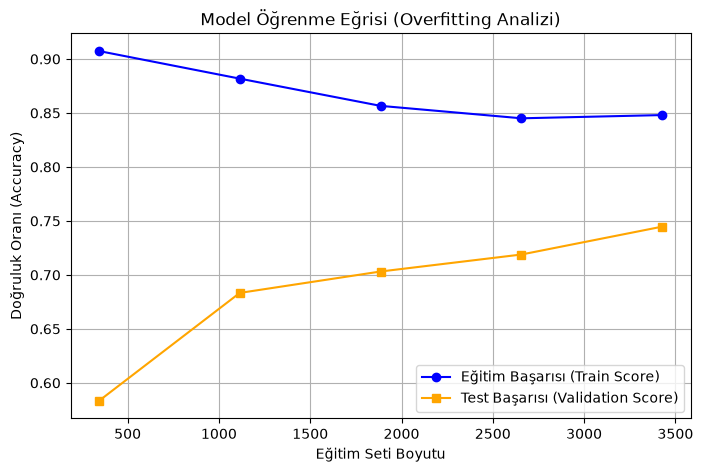

In [11]:
train_sizes, train_scores, test_scores = learning_curve(
    nb_model, x_train_vector, y_train, cv=3, scoring='accuracy', 
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Görselleştirme
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Eğitim Başarısı (Train Score)', marker='o', color='blue')
plt.plot(train_sizes, test_mean, label='Test Başarısı (Validation Score)', marker='s', color='orange')

plt.title('Model Öğrenme Eğrisi (Overfitting Analizi)')
plt.xlabel('Eğitim Seti Boyutu')
plt.ylabel('Doğruluk Oranı (Accuracy)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [19]:
df=pd.read_csv('data2/dataset.csv')
print(f'Toplam makale sayısı:{len(df)}')
display(df['category'].value_counts())
display(df.head(2))

Toplam makale sayısı:8635


category
bilgisayar_bilimleri    2658
saglik                  2369
tarih                   1670
finans                  1493
spor                     445
Name: count, dtype: int64

,category,journal,title,abstract
0,bilgisayar_bilimleri,adyujsci,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,Bu çalışmada iki problem incelenmiştir. Genel ...
1,bilgisayar_bilimleri,adyujsci,CMS Açık Veri ile Eğitici Higgs Çalışması,"Kompakt Müon Solenoid (CMS) Deneyi, CERN’in Bü..."


In [20]:
df['full_text']=df['title'].fillna('')+". "+df['abstract'].fillna('')
df['processed_text']=df['full_text'].apply(preprocess)
display(df[['full_text','processed_text']].tail(2))

,full_text,processed_text
8633,Uluslararası ticarette risk yönetimi bağlamınd...,UluslararasıticaretteriskyönetimibağlamındaInc...
8634,Örgüt kültürünün sıkılık/esneklik boyutunda se...,Örgütkültürününsıkılık esneklikboyutundasektör...


In [22]:
x_train, x_test, y_train, y_test = train_test_split(df['processed_text'], df['category'], test_size=0.2, random_state=42)
vectorizer=TfidfVectorizer(ngram_range=(1,2),min_df=3)
x_train_vector=vectorizer.fit(x_train)
x_train_vector=vectorizer.transform(x_train)
x_test_vector=vectorizer.transform(x_test)

nb_model=MultinomialNB(alpha=0.1)
nb_model.fit(x_train_vector,y_train)
y_prediction=nb_model.predict(x_test_vector)
print("Model Doğruluk Oranı (Accuracy):", accuracy_score(y_test, y_prediction))
print("\nSınıflandırma Raporu:\n", classification_report(y_test, y_prediction))

Model Doğruluk Oranı (Accuracy): 0.7602779386218876

Sınıflandırma Raporu:
                       precision    recall  f1-score   support

bilgisayar_bilimleri       0.69      0.88      0.78       535
              finans       0.74      0.58      0.65       294
              saglik       0.86      0.87      0.86       482
                spor       0.90      0.65      0.75        80
               tarih       0.74      0.60      0.66       336

            accuracy                           0.76      1727
           macro avg       0.79      0.72      0.74      1727
        weighted avg       0.77      0.76      0.76      1727



In [23]:
metin = ["""Günümüzde devletler yapay zeka araştırma ve geliştirme çalışmalarına ve yatırımlarına büyük önem vermektedirler. Küresel alandaki rekabetten yararlanarak dünya üzerinde hakimiyet kurmak isteyen ülkeler bu alanda yenilikleri ilk uygulayan devlet olarak üstünlük gücünü ele geçirmek amacındadırlar. Yapay zeka alanındaki küresel rekabette önemli bir yere sahip olan Çin 2017 yılında Ulusal Yapay Zeka Stratejisi’ni kamuoyuna sunması ile yapay zekaya yönelik yapılan mevcut yatırımlara resmilik kazandıran, Devlet Konseyi’nin Yapay Zeka Geliştirme Ulusal Stratejisi belgesini yayınladı. Küresel çapta yapay zeka hakimiyeti açısından oldukça büyük öneme sahip olan bu belge diğer devletleri de ulusal yapay zeka stratejisi oluşturma yönünde teşvik etti. Aynı zamanda Çin’in ülke genelinde bu alanda hızlı yaşanan bilimsel araştırma ve geliştirmeler ile eğitimin yapay zeka alanındaki yenilikler bakımından önemini vurgulayan bir nitelik de taşımaktadır. Ayrıca bu süreç, Çin’de eğitimde yapay zeka teknolojileri deney ve çalışmalarının yoğunluk kazanması, yatırım ölçeklerinin oldukça büyük oluşu, eğitimde üst seviye yapay zeka teknolojilerini geliştirmesi dünyadaki eğitimsel yapay zeka gelişimindeki güç dengelerinin yönünü değiştirmeye başladı. Şimdilerde olduğu gibi, eğitimsel yapay zekadaki gelişmelerle küresel yönden gelecekte de ne denli değiştirip dönüştüreceğinin de işaretlerini vermektedir. Dünya genelinde oldukça büyük etki yapan bu belge, pek çok ülke tarafından yapay zekanın stratejik kullanımını amaçlayan “Ulusal Yapay Zeka Stratejileri”nin hazırlanmasına neden olmuştur. Bu makalede, Çin hükümeti tarafından yayınlanan yapay zeka gelişimi için eğitim kurumlarının ulusal ve bölgesel strateji alanlarında etkin olarak yer alan Ulusal Yapay Zeka Stratejisi eğitimsel açıdan ele alınmaktadır. Hükümet politikalarına göre yapay zeka eğitimin gelişimini bir analiz yoluyla tasvir ederken, PISA sınavı sonuçları ile de bağlantı kurularak açıklanmaya çalışılmaktadır. Ayrıca Çin’deki Uluslararası Yapay Zeka Geliştirme Stratejisini eğitimsel alanda hızla uygulamalarının ve gelişmelerine yönelik yaptırımların neler olduğu onu bu yönde diğer ülkelerden ayıran özellikleri ortaya konulmaya çalışılmaktadır. Ayrıca Çin’deki bu gelişimin sadece yapay zeka teknolojilerinin tasarımı değil eğitim sisteminin değişim ve dönüşümünde etkili olan nedenler ve çözümlere ilişkin yaklaşımlara yer verilmektedir. Çin başta olmak üzere, diğer birçok ülke ulusal yapay zeka stratejisi belgelerini yayınlayarak yapay zeka alanında gelişmeyi kalkınma amaçları arasında yerleştirmişlerdir. Türkiye’de küresel çapta yaşanan yapay zekadaki hızlı gelişimin dışında olmamak için yapay zeka teknolojisine yönelik 2021 yılında Ulusal Yapay Zeka Strateji’ni yayınlayarak, eğitimsel yapay zeka teknolojisini daha fazla gelişmek zorunda kalmaktadır. Bu çalışma, Ulusal Yapay Zeka Stratejileri kapsamında eğitimde yapay zekanın gelişimi üzerine genel bir çerçeve belirleyerek yapay zeka teknolojisinin genel olarak küresel düzeyde ve Çin ile Türkiye ulusal yapay zeka stratejilerinin eğitim yönünden güçlü ve zayıf yönlerini değerlendirmektedir. Ayrıca Çin’in ulusal yapay zeka stratejisi ve eylem planında yapay zekanın eğitimsel yönünü analiz ederek Türkiye’nin eğitimsel yönden yapay zekayı merkezi alan bir ekosistem oluşturması ve gelişimini sağlayabilmesinde izleyeceği stratejiye yönelik öneriler sunmayı amaçlamaktadır."""]
islenmis = preprocess(metin[0]) # Liste olduğu için [0] ile string'e ulaşıyoruz
metin_vec = vectorizer.transform([islenmis])

# Olasılıkları ve tahmini gör
tahmin = nb_model.predict(metin_vec)
olasiliklar = nb_model.predict_proba(metin_vec)

print("Tahmin Edilen Kategori:", tahmin[0])
for sinif, prob in zip(nb_model.classes_, olasiliklar[0]):
    print(f"{sinif} -> Olasılık: {prob:.4f}")

Tahmin Edilen Kategori: bilgisayar_bilimleri
bilgisayar_bilimleri -> Olasılık: 0.4544
finans -> Olasılık: 0.0663
saglik -> Olasılık: 0.0776
spor -> Olasılık: 0.0005
tarih -> Olasılık: 0.4011


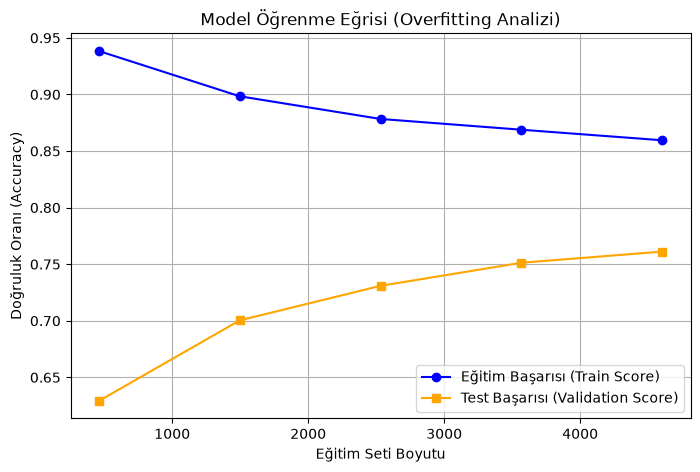

In [25]:
train_sizes, train_scores, test_scores = learning_curve(
    nb_model, x_train_vector, y_train, cv=3, scoring='accuracy', 
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Görselleştirme
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Eğitim Başarısı (Train Score)', marker='o', color='blue')
plt.plot(train_sizes, test_mean, label='Test Başarısı (Validation Score)', marker='s', color='orange')

plt.title('Model Öğrenme Eğrisi (Overfitting Analizi)')
plt.xlabel('Eğitim Seti Boyutu')
plt.ylabel('Doğruluk Oranı (Accuracy)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

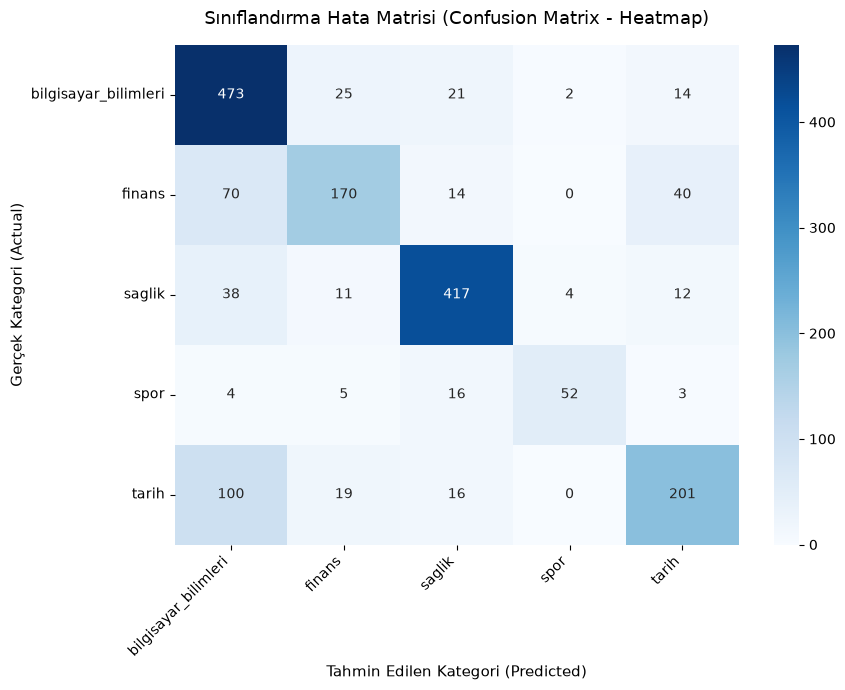

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

aktif_model = nb_model  # veya nb_model
aktif_X_test = x_test_vector # Test verinin vektör hali

# Tahminleri alıyoruz
y_pred = aktif_model.predict(aktif_X_test)

# Confusion Matrix hesaplama
cm = confusion_matrix(y_test, y_pred, labels=aktif_model.classes_)

# Isı Haritasını (Heatmap) Çizdirme
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=aktif_model.classes_, 
            yticklabels=aktif_model.classes_)

plt.title('Sınıflandırma Hata Matrisi (Confusion Matrix - Heatmap)', fontsize=13, pad=15)
plt.xlabel('Tahmin Edilen Kategori (Predicted)', fontsize=11)
plt.ylabel('Gerçek Kategori (Actual)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()